# Sprawozdanie — Zajęcia 1

**Przedmiot:** Uczenie głębokie w systemach rozpoznawania i przetwarzania mowy
**Zajęcia nr / temat:** 1 — Sekwencje i sygnał mowy: od fali dźwiękowej do reprezentacji
**Autor / grupa:** Adam Pastuszak / …
**Data:** …

## 1. Cel ćwiczenia

Celem było zamienić nagranie mowy na reprezentację, którą można podać sieci neuronowej

Dla trzech nagrań (samogłoska, wyraz, zdanie) policzyłem log-mel i MFCC, porównałem je i sprawdziłem, jak na spektrogram wpływa n_fft i hop_length

## 2. Metoda i implementacja

Narzędzia: Python w Google Colab, librosa, numpy, matplotlib

Nagrania: samogłoska „a” (A.mp3), wyraz „kasa” (Kasa.mp3) i zdanie „Kot śpi na szafie, a pies pod stołem” (Kot_śpi_na_szafie_a.mp3), pliki mp3 24 kHz mono

Wczytanie z konwersją do 16 kHz mono i obcięciem ciszy na brzegach (próg 40 dB), po obcięciu nagrania mają 0,38 s, 0,58 s i 2,50 s

Parametry bazowe: n_fft 512 (32 ms), hop_length 160 (10 ms), 64 pasma mel, 13 współczynników MFCC

MFCC liczone z log-mel, więc obie reprezentacje mają tę samą oś czasu

Eksperyment A: n_fft 256, 512 i 1024 przy hop_length 160

Eksperyment B: hop_length 80, 160 i 320 przy n_fft 512

Wszystkie spektrogramy mają tę samą skalę od −80 do 0 dB

### 2.1 Instalacja i parametry

In [ ]:
!pip -q install librosa soundfile matplotlib numpy

In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Audio, display

SR = 16000
N_FFT = 512
HOP_LENGTH = 160
N_MELS = 64
N_MFCC = 13
TOP_DB = 80

NAGRANIA = {
    "samogłoska": "A.mp3",
    "wyraz": "Kasa.mp3",
    "zdanie": "Kot_śpi_na_szafie_a.mp3",
}

### 2.2 Wczytanie nagrań

W Colab wgraj wszystkie trzy pliki naraz

In [ ]:
from google.colab import files
files.upload()

In [2]:
def wczytaj(sciezka):
    y, _ = librosa.load(sciezka, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=40)
    return y


sygnaly = {nazwa: wczytaj(plik) for nazwa, plik in NAGRANIA.items()}

for nazwa, y in sygnaly.items():
    print(f"{nazwa:>10}: {len(y):6d} próbek, {len(y) / SR:.2f} s")
    display(Audio(y, rate=SR))

samogłoska:   6144 próbek, 0.38 s


     wyraz:   9216 próbek, 0.58 s


    zdanie:  39936 próbek, 2.50 s


### 2.3 Log-mel i MFCC

In [3]:
def log_mel(y, n_fft=N_FFT, hop_length=HOP_LENGTH):
    S = librosa.feature.melspectrogram(
        y=y, sr=SR, n_fft=n_fft, hop_length=hop_length, n_mels=N_MELS
    )
    return librosa.power_to_db(S, ref=np.max, top_db=TOP_DB)


def mfcc(S_db):
    return librosa.feature.mfcc(S=S_db, n_mfcc=N_MFCC)


def stft_db(y, n_fft, hop_length=HOP_LENGTH):
    D = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop_length)) ** 2
    return librosa.power_to_db(D, ref=np.max, top_db=TOP_DB)


cechy = {}
for nazwa, y in sygnaly.items():
    S_db = log_mel(y)
    M = mfcc(S_db)
    cechy[nazwa] = (S_db, M)
    print(f"{nazwa:>10}: log-mel {S_db.shape}, MFCC {M.shape}, "
          f"wejście RNN [T, cechy] {S_db.T.shape}")

samogłoska: log-mel (64, 39), MFCC (13, 39), wejście RNN [T, cechy] (39, 64)
     wyraz: log-mel (64, 58), MFCC (13, 58), wejście RNN [T, cechy] (58, 64)
    zdanie: log-mel (64, 250), MFCC (13, 250), wejście RNN [T, cechy] (250, 64)


In [4]:
def rysuj_mfcc(M, ax, hop_length=HOP_LENGTH, lim=None):
    lim = lim or np.abs(M[1:]).max()
    koniec = M.shape[1] * hop_length / SR
    img = ax.imshow(M, origin="lower", aspect="auto", interpolation="nearest",
                    cmap="coolwarm", vmin=-lim, vmax=lim,
                    extent=[0, koniec, -0.5, M.shape[0] - 0.5])
    ax.set_yticks(range(M.shape[0]))
    ax.set(xlabel="czas [s]", ylabel="współczynnik")
    return img


def rysuj_trzy(nazwa, y, S_db, M):
    fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True, constrained_layout=True)
    librosa.display.waveshow(y, sr=SR, ax=ax[0])
    ax[0].set(title=f"{nazwa}: przebieg czasowy", ylabel="amplituda")
    img = librosa.display.specshow(S_db, sr=SR, hop_length=HOP_LENGTH, x_axis="time",
                                   y_axis="mel", ax=ax[1], vmin=-TOP_DB, vmax=0)
    ax[1].set_title(f"{nazwa}: log-mel")
    fig.colorbar(img, ax=ax[1], format="%+2.0f dB")
    img = rysuj_mfcc(M, ax[2])
    ax[2].set_title(f"{nazwa}: MFCC")
    fig.colorbar(img, ax=ax[2])
    plt.show()

## 3. Wyniki

### 3.1 Reprezentacje każdego nagrania (rys. 1–3)

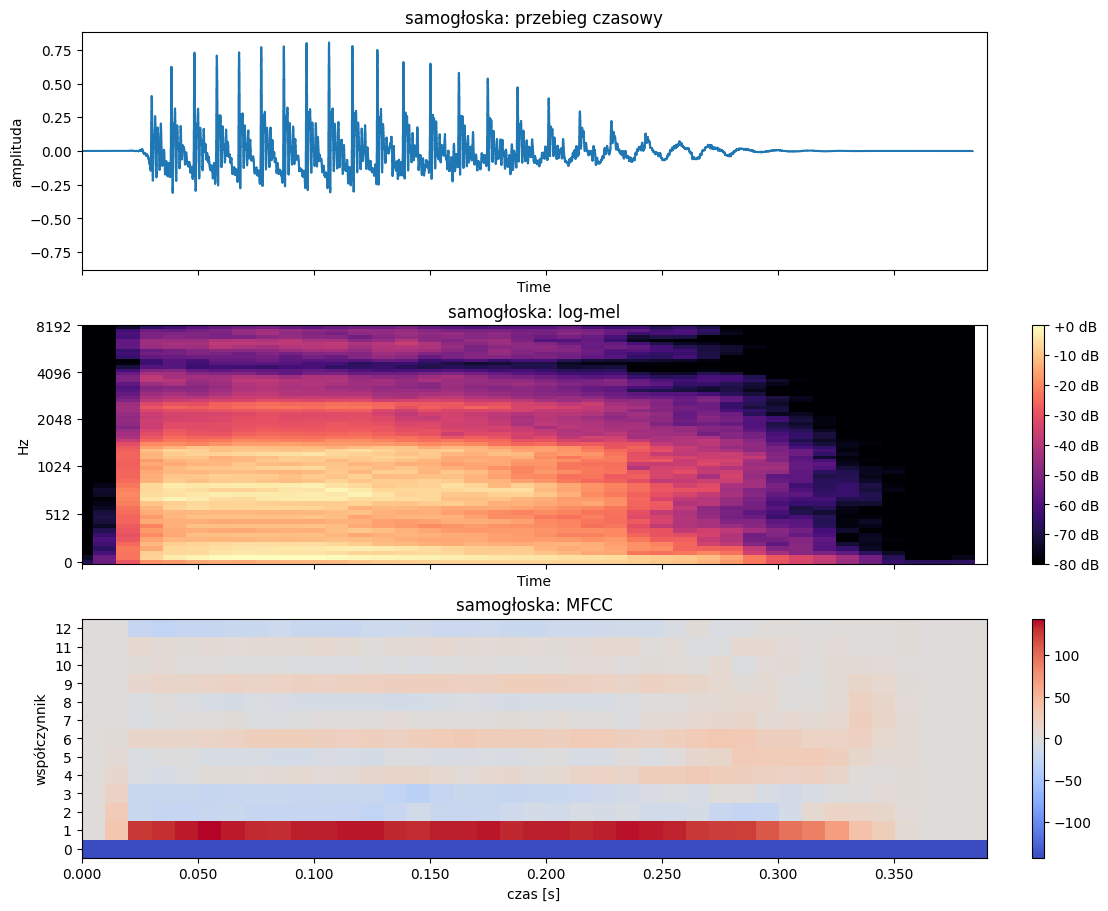

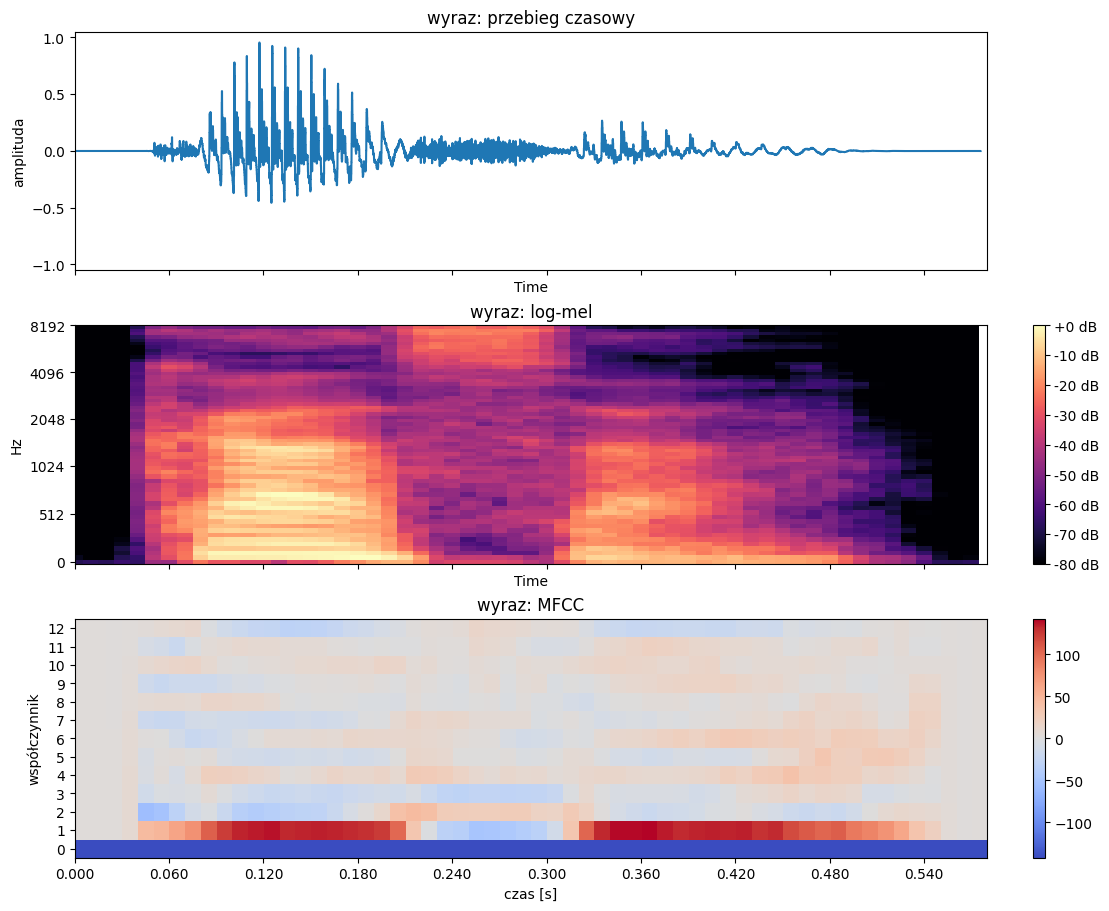

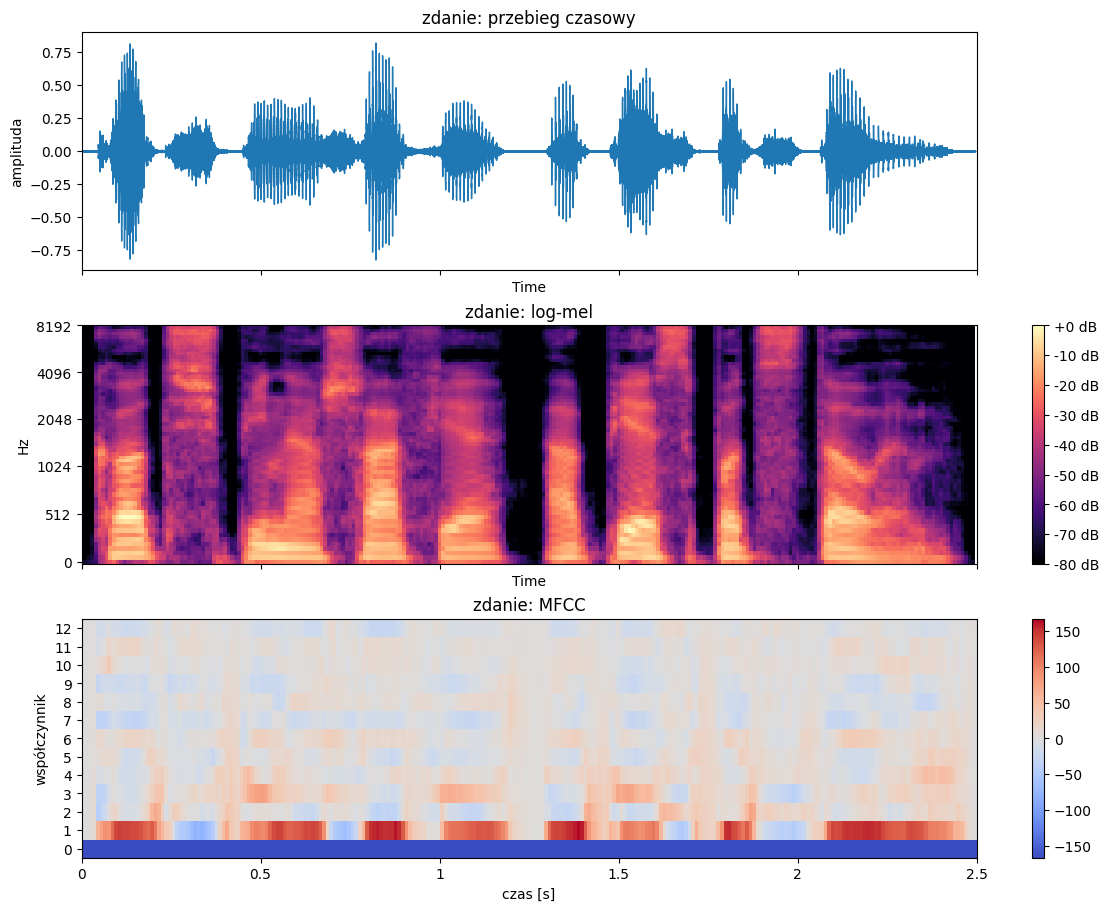

In [5]:
for nazwa, y in sygnaly.items():
    rysuj_trzy(nazwa, y, *cechy[nazwa])

### 3.2 Porównanie nagrań (rys. 4, tabela 1)

Cisza to procent ramek o 30 dB cichszych od maksimum, zmienność MFCC to średnie odchylenie współczynników 1–12 w czasie, a zmiana log-mel to średnia różnica między sąsiednimi ramkami w dB

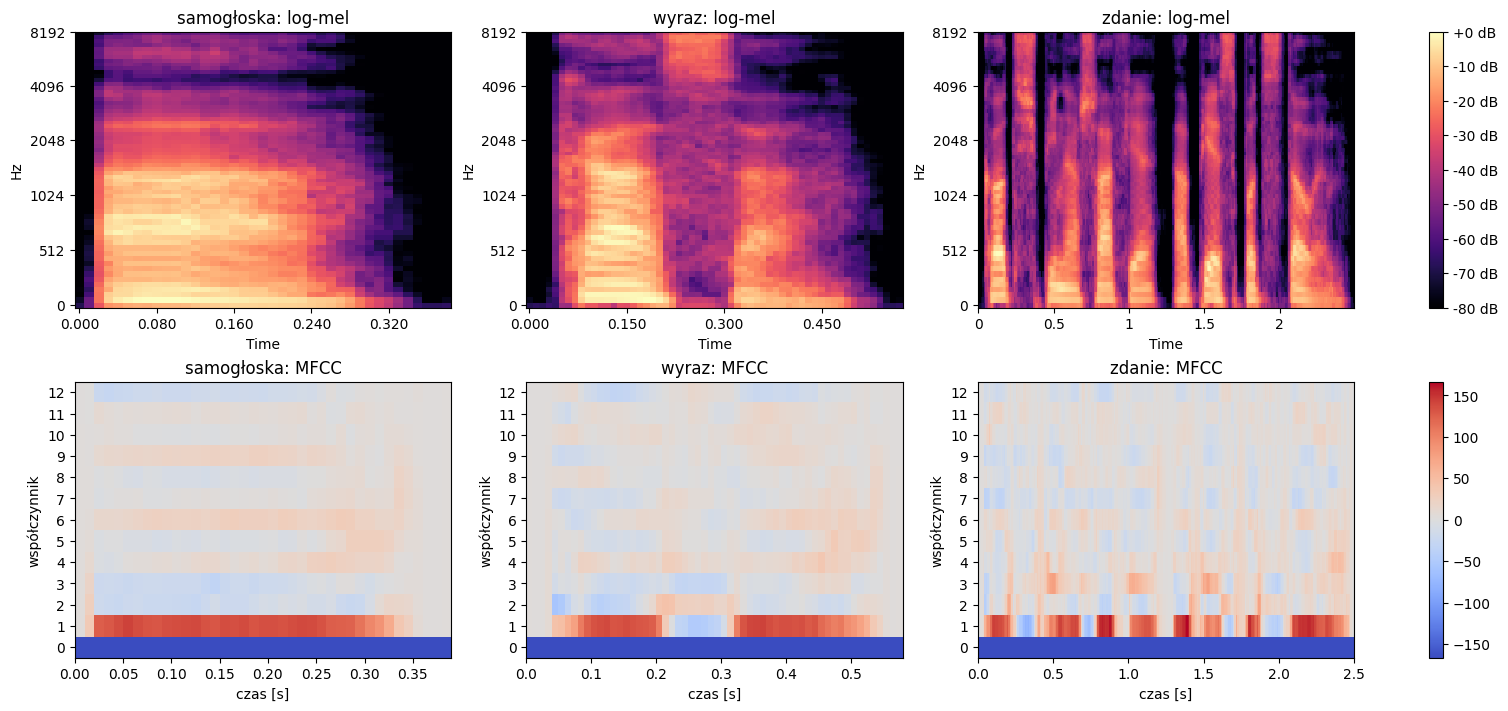

  nagranie | czas [s] | ramki T | cisza [%] | zmienność MFCC | zmiana log-mel [dB]
samogłoska |     0.38 |      39 |      28.2 |          11.31 |                3.47
     wyraz |     0.58 |      58 |      20.7 |          14.96 |                3.66
    zdanie |     2.50 |     250 |      18.0 |          16.93 |                4.21


In [6]:
lim = max(np.abs(M[1:]).max() for _, M in cechy.values())
fig, ax = plt.subplots(2, 3, figsize=(15, 7), constrained_layout=True)
for k, (nazwa, (S_db, M)) in enumerate(cechy.items()):
    img1 = librosa.display.specshow(S_db, sr=SR, hop_length=HOP_LENGTH, x_axis="time",
                                    y_axis="mel", ax=ax[0, k], vmin=-TOP_DB, vmax=0)
    ax[0, k].set_title(f"{nazwa}: log-mel")
    ax[0, k].xaxis.set_major_locator(plt.MaxNLocator(5))
    img2 = rysuj_mfcc(M, ax[1, k], lim=lim)
    ax[1, k].set_title(f"{nazwa}: MFCC")
fig.colorbar(img1, ax=ax[0], format="%+2.0f dB")
fig.colorbar(img2, ax=ax[1])
plt.show()

print(f"{'nagranie':>10} | {'czas [s]':>8} | {'ramki T':>7} | {'cisza [%]':>9} | "
      f"{'zmienność MFCC':>14} | {'zmiana log-mel [dB]':>19}")
for nazwa, y in sygnaly.items():
    S_db, M = cechy[nazwa]
    rms = librosa.feature.rms(y=y, frame_length=N_FFT, hop_length=HOP_LENGTH)[0]
    cisza = 100 * np.mean(librosa.amplitude_to_db(rms, ref=np.max) < -30)
    zmiennosc = np.mean(np.std(M[1:], axis=1))
    zmiana = np.mean(np.abs(np.diff(S_db, axis=1)))
    print(f"{nazwa:>10} | {len(y) / SR:8.2f} | {S_db.shape[1]:7d} | {cisza:9.1f} | "
          f"{zmiennosc:14.2f} | {zmiana:19.2f}")

### 3.3 Eksperyment A, n_fft (rys. 5)

hop_length 160, spektrogram STFT pokazany do 4 kHz, żeby było widać harmoniczne

| n_fft | okno | rozstaw prążków |
|---|---|---|
| 256 | 16 ms | 62,5 Hz |
| 512 | 32 ms | 31,25 Hz |
| 1024 | 64 ms | 15,6 Hz |

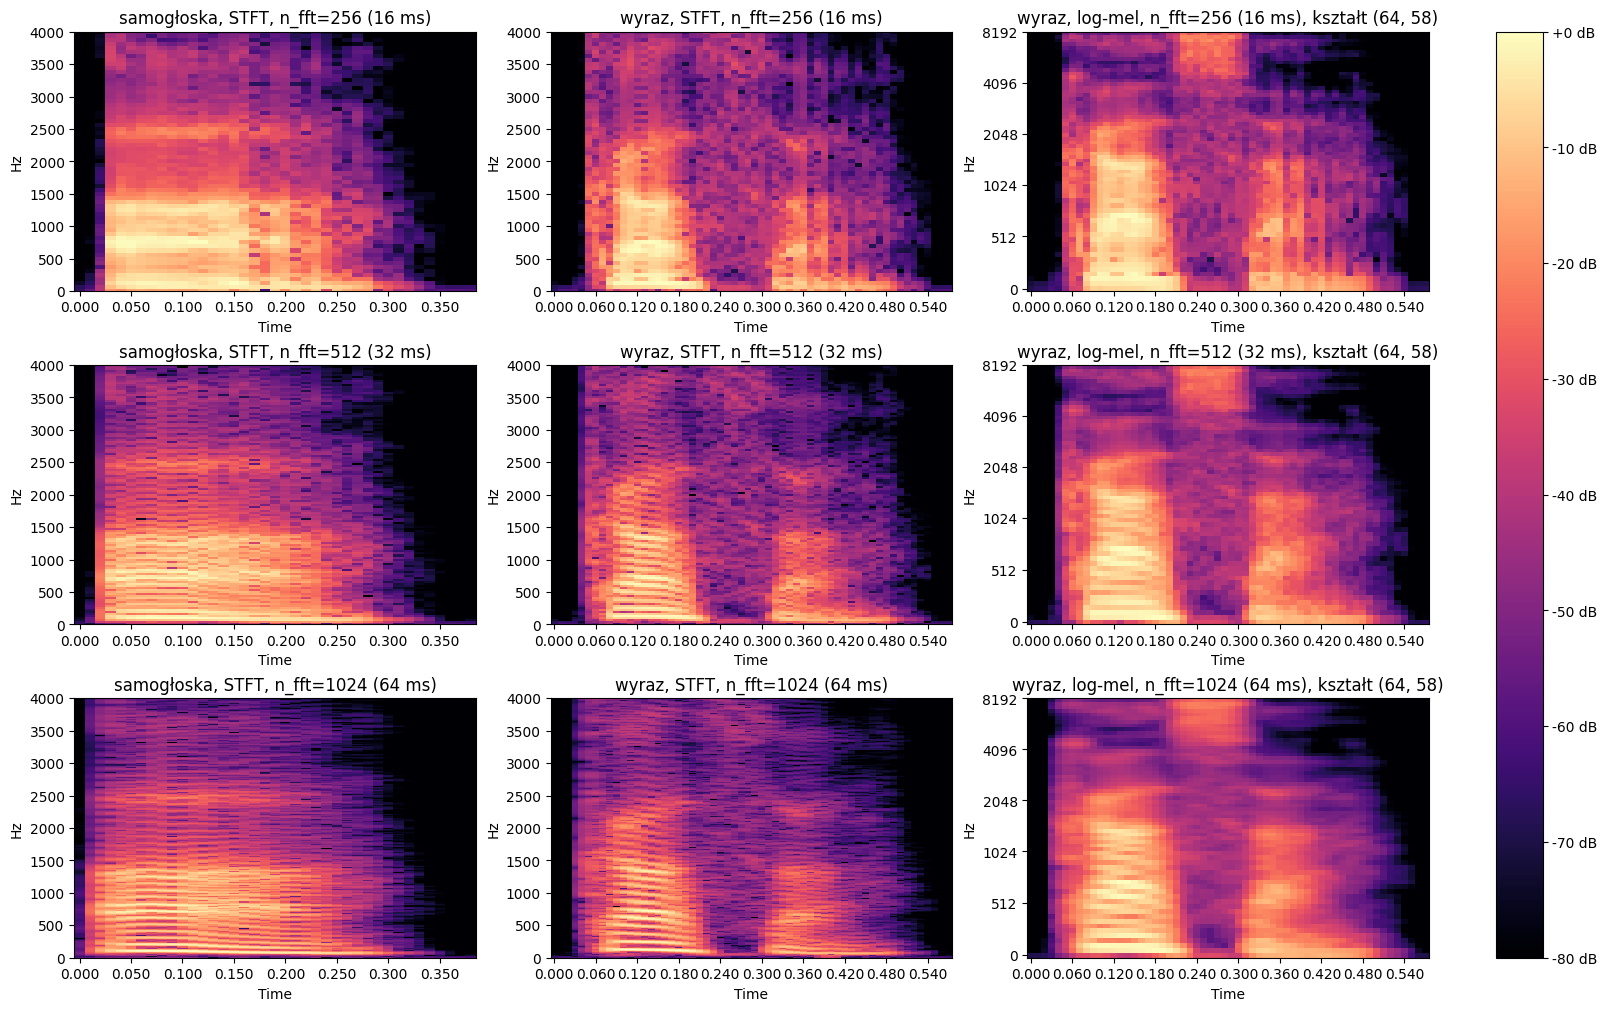

In [7]:
OKNA = [256, 512, 1024]
fig, ax = plt.subplots(len(OKNA), 3, figsize=(16, 10), constrained_layout=True)
for i, n_fft in enumerate(OKNA):
    opis = f"n_fft={n_fft} ({1000 * n_fft / SR:.0f} ms)"
    for j, nazwa in enumerate(["samogłoska", "wyraz"]):
        img = librosa.display.specshow(stft_db(sygnaly[nazwa], n_fft), sr=SR, n_fft=n_fft,
                                       hop_length=HOP_LENGTH, x_axis="time",
                                       y_axis="linear", ax=ax[i, j],
                                       vmin=-TOP_DB, vmax=0)
        ax[i, j].set_ylim(0, 4000)
        ax[i, j].set_title(f"{nazwa}, STFT, {opis}")
    S_db = log_mel(sygnaly["wyraz"], n_fft=n_fft)
    librosa.display.specshow(S_db, sr=SR, hop_length=HOP_LENGTH, x_axis="time",
                             y_axis="mel", ax=ax[i, 2], vmin=-TOP_DB, vmax=0)
    ax[i, 2].set_title(f"wyraz, log-mel, {opis}, kształt {S_db.shape}")
fig.colorbar(img, ax=ax, format="%+2.0f dB")
plt.show()

### 3.4 Eksperyment B, hop_length (rys. 6, tabela 2)

n_fft 512

hop_length | krok [ms] | ramki/s |    T | 1 + N // hop
        80 |         5 |     200 |  116 |          116
       160 |        10 |     100 |   58 |           58
       320 |        20 |      50 |   29 |           29


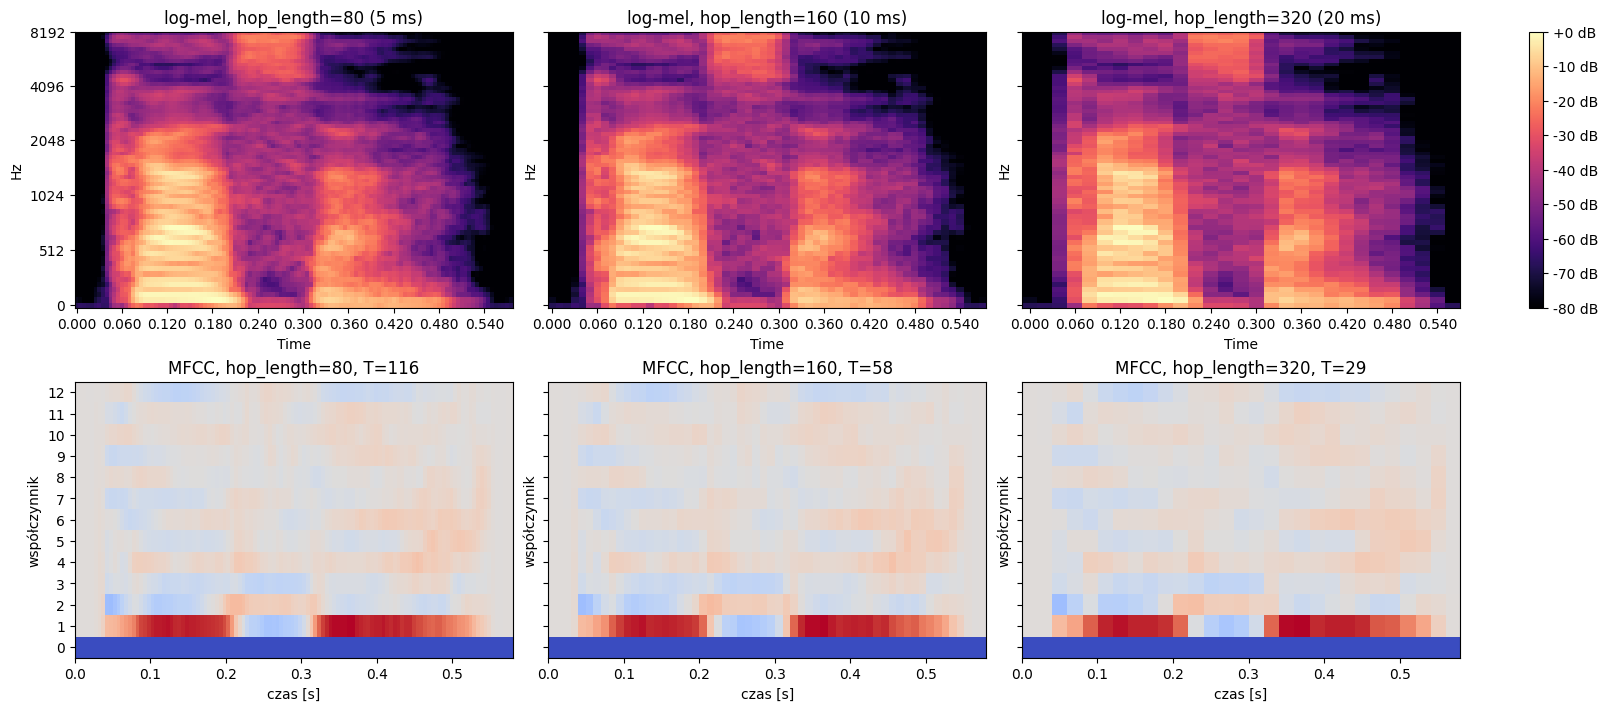

In [8]:
KROKI = [80, 160, 320]
y = sygnaly["wyraz"]
fig, ax = plt.subplots(2, len(KROKI), figsize=(16, 7), sharey="row", constrained_layout=True)
print(f"{'hop_length':>10} | {'krok [ms]':>9} | {'ramki/s':>7} | {'T':>4} | {'1 + N // hop':>12}")
for k, hop in enumerate(KROKI):
    S_db = log_mel(y, hop_length=hop)
    img = librosa.display.specshow(S_db, sr=SR, hop_length=hop, x_axis="time",
                                   y_axis="mel", ax=ax[0, k], vmin=-TOP_DB, vmax=0)
    ax[0, k].set_title(f"log-mel, hop_length={hop} ({1000 * hop / SR:.0f} ms)")
    rysuj_mfcc(mfcc(S_db), ax[1, k], hop_length=hop)
    ax[1, k].set_title(f"MFCC, hop_length={hop}, T={S_db.shape[1]}")
    print(f"{hop:10d} | {1000 * hop / SR:9.0f} | {SR // hop:7d} | {S_db.shape[1]:4d} | "
          f"{1 + len(y) // hop:12d}")
fig.colorbar(img, ax=ax[0], format="%+2.0f dB")
plt.show()

### 3.5 Pomiary fragmentów (tabela 3)

Czasy fragmentów odczytane z rys. 1–3, mediana to częstotliwość, poniżej której jest połowa energii fragmentu, f0 to ton podstawowy z pyin (kreska, gdy fragment jest bezdźwięczny), a c0 i c1 to średnie wartości MFCC

In [9]:
FRAGMENTY = [
    ("samogłoska", "a, część stała", 0.02, 0.24),
    ("samogłoska", "a, wygasanie", 0.26, 0.38),
    ("wyraz", "k (wybuch)", 0.04, 0.07),
    ("wyraz", "a (1. sylaba)", 0.07, 0.21),
    ("wyraz", "s", 0.22, 0.31),
    ("wyraz", "a (2. sylaba)", 0.33, 0.48),
    ("zdanie", "o w „kot”", 0.07, 0.23),
    ("zdanie", "ś w „śpi”", 0.25, 0.38),
    ("zdanie", "sz w „szafie”", 0.71, 0.77),
    ("zdanie", "f w „szafie”", 0.93, 1.00),
    ("zdanie", "pauza po przecinku", 1.19, 1.29),
    ("zdanie", "a po przecinku", 1.29, 1.43),
    ("zdanie", "s w „pies”", 1.63, 1.70),
    ("zdanie", "s w „stołem”", 1.89, 2.02),
]

widma, tony = {}, {}
for nazwa, y in sygnaly.items():
    widma[nazwa] = np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP_LENGTH)) ** 2
    f0, dzwieczna, _ = librosa.pyin(y, fmin=50, fmax=400, sr=SR,
                                    frame_length=1024, hop_length=HOP_LENGTH)
    tony[nazwa] = (f0, dzwieczna)
czestotliwosci = librosa.fft_frequencies(sr=SR, n_fft=N_FFT)

print(f"{'nagranie':>10} | {'fragment':<20} | {'czas [s]':>11} | {'mediana [Hz]':>12} | "
      f"{'f0 [Hz]':>7} | {'c0':>6} | {'c1':>6} | {'zmienność MFCC':>14}")
for nazwa, opis, start, koniec in FRAGMENTY:
    S_db, M = cechy[nazwa]
    t = librosa.frames_to_time(np.arange(S_db.shape[1]), sr=SR, hop_length=HOP_LENGTH)
    m = (t >= start) & (t < koniec)
    energia = np.cumsum(widma[nazwa][:, m].mean(axis=1))
    mediana = czestotliwosci[np.searchsorted(energia, energia[-1] / 2)]
    f0, dzwieczna = tony[nazwa][0][m], tony[nazwa][1][m]
    f0 = f"{np.nanmedian(f0):7.0f}" if dzwieczna.mean() >= 0.5 else f"{'—':>7}"
    print(f"{nazwa:>10} | {opis:<20} | {start:5.2f}–{koniec:4.2f} | {mediana:12.0f} | {f0} | "
          f"{M[0, m].mean():6.0f} | {M[1, m].mean():6.0f} | {np.std(M[1:, m], axis=1).mean():14.1f}")

  nagranie | fragment             |    czas [s] | mediana [Hz] | f0 [Hz] |     c0 |     c1 | zmienność MFCC
samogłoska | a, część stała       |  0.02–0.24 |          688 |     100 |   -240 |    135 |            3.6
samogłoska | a, wygasanie         |  0.26–0.38 |           62 |      73 |   -539 |     68 |           10.0
     wyraz | k (wybuch)           |  0.04–0.07 |         1250 |       — |   -347 |     52 |            4.3
     wyraz | a (1. sylaba)        |  0.07–0.21 |          562 |     121 |   -232 |    124 |            9.0
     wyraz | s                    |  0.22–0.31 |         6812 |       — |   -322 |    -32 |            5.7
     wyraz | a (2. sylaba)        |  0.33–0.48 |          156 |      66 |   -370 |    130 |            7.3
    zdanie | o w „kot”            |  0.07–0.23 |          500 |     127 |   -373 |    120 |           12.9
    zdanie | ś w „śpi”            |  0.25–0.38 |         4062 |       — |   -335 |    -52 |            7.8
    zdanie | sz w „szafie”        | 

## 4. Analiza i interpretacja

### 4.1 Hipotezy (przed uruchomieniem)

- samogłoska: stałe poziome pasma formantów, MFCC prawie takie same w każdej ramce
- wyraz: na początku kreska od „k”, potem „a”, plama szumu powyżej ok. 4 kHz od „s” i znowu „a”
- zdanie: ciemne pasy w pauzach, MFCC trudne do odczytania
- n_fft 1024: osobne prążki harmonicznych, ale rozmyte granice, przy 256 odwrotnie
- hop_length: zmienia tylko liczbę ramek

### 4.2 Obserwacje

Samogłoska (rys. 1)
- od 0,02 do 0,24 s obraz jest prawie stały, formanty „a” są w okolicy 500–1400 Hz i 2,5 kHz, ton ok. 100 Hz
- MFCC w tym czasie prawie się nie zmieniają (zmienność 3,6)
- od 0,25 s głos wygasa, znikają wysokie pasma, a c0 spada z −240 do −539

Wyraz (rys. 2)
- 0,04–0,07 s słaby szum bez harmonicznych, to „k”
- 0,07–0,21 s pierwsze „a”, ton 121 Hz
- 0,22–0,31 s „s”, plama od ok. 4–5 kHz w górę, mediana 6812 Hz, c1 spada do −32
- 0,33–0,48 s drugie „a”, ciszej i niżej (66 Hz), intonacja opada na końcu

Zdanie (rys. 3)
- pauza po przecinku 1,19–1,29 s, tu jest najniższe c0 (−631)
- krótkie przerwy ok. 0,43, 1,45, 1,75 i 2,04 s to zwarcia przed „p” i „t”
- pięć plam szumu: „ś” 0,25–0,38 s, „sz” 0,71–0,77 s, „f” 0,93–1,00 s, „s” 1,63–1,70 s i 1,89–2,02 s
- „s” ma szum najwyżej (ok. 6,7 kHz), „ś” niżej (4,1 kHz), „sz” najniżej (3,3 kHz), a „f” jest najsłabsze
- w „stołem” między 2,08 a 2,30 s pasmo w okolicy 1 kHz schodzi w dół i wraca, to ruch formantów, w samogłosce tego nie ma
- z MFCC głosek się nie odczyta, ale c1 jest dodatnie w samogłoskach (od +120 do +130) i ujemne w szumach (od −31 do −52)

Porównanie (rys. 4, tabela 1)
- zmienność MFCC (11,31 → 14,96 → 16,93) i zmiana log-mel (3,47 → 3,66 → 4,21 dB) rosną od samogłoski do zdania
- samogłoska wypada blisko wyrazu, bo jest krótka i ok. 1/3 to wygasanie
- cisza wyszła najwyższa w samogłosce (28,2%) przez wygasanie, więc ten wskaźnik nie mierzy złożoności

Eksperyment A (rys. 5)
- 256: harmoniczne zlane w szerokie pasma, ale granice ostre, np. „s” w wyrazie od 0,22 do 0,31 s
- 512: harmoniczne widać poniżej ok. 1,5 kHz
- 1024: osobne prążki do ok. 3,5 kHz, ale granice rozmyte, samogłoska zaczyna się już od ok. 0 s zamiast 0,025 s
- przy tonie 100 Hz okno 16 ms łapie 1,5 okresu, a 64 ms 6 okresów, dlatego dopiero długie okno rozdziela harmoniczne
- na log-mel efekt jest słabszy, bo wysokie pasma mel są szerokie, a rozmiar macierzy zostaje ten sam (64, 58)

Eksperyment B (rys. 6, tabela 2)
- ramek jest 116 / 58 / 29, dokładnie 1 + N // hop_length
- w pionie obraz się nie zmienia, przy 320 granice robią się schodkowe, a przy 80 jest tylko 2 razy więcej danych

### 4.3 Weryfikacja hipotez

- samogłoska: tak, ale nie przewidziałem wygasania
- wyraz: częściowo, „s” się zgadza, ale „k” to nie kreska, tylko ok. 30 ms słabego szumu
- zdanie: pauza tak, MFCC częściowo, bo po c1 widać, gdzie jest samogłoska, a gdzie szum
- n_fft i hop_length: tak

### 4.4 Ograniczenia

- dB są liczone względem maksimum każdego nagrania, więc nie da się porównać głośności między nagraniami
- nagrania są krótkie, samogłoska ma tylko 0,38 s
- mp3 to kompresja stratna, do tego przeliczenie z 24 na 16 kHz
- granice fragmentów są odczytane z wykresów, więc dokładność to kilka ramek
- jest tylko jeden głos

## 5. Wnioski

- w pojedynczej głosce widać to, co stałe, czyli formanty i harmoniczne, a MFCC to prawie te same kolumny
- w mowie ciągłej liczą się zmiany: przejścia samogłoska–szum, zwarcia, pauzy i ruch formantów
- na log-mel da się nawet odróżnić „s”, „ś” i „sz”, a z MFCC wzrokowo czytelne są głównie c0 (głośność, pauzy) i c1 (samogłoska czy szum)
- n_fft to kompromis między czasem a częstotliwością, 512 (32 ms) jest dobrym środkiem dla mowy
- hop_length zmienia tylko liczbę ramek, czyli ile danych dostaje model
- do poprawy: dłuższa samogłoska i więcej mówców